# 03检验解调数据与原始数据是否一致

本 notebook **独立**读取两个文件做比对：

- `qpsk_03_capture.npz` —— 发送端留下的**真值比特**（发之前就知道该收到什么）
- `qpsk_04_demod.npz`  —— 接收端**解出来的比特**

两者逐比特比对，给出 BER、错误位置、EVM、星座、眼图、判决余量，最后输出 PASS/FAIL。

判定不是"看起来对就行"，而是五条量化门限全过才算 PASS：

| 判据 | 门限 | 依据 |
|---|---|---|
| 误码率 BER | 必须为 **0** | 环回无外部干扰，任何误码都是缺陷 |
| 单帧最差 EVM | < **5 %** | 对应 SNR ≈ 26 dB，实测 0.3~2.3 % |
| 帧间 t0 抖动 | < **0.5** 样点 | 定时捕获的稳定性 |
| 残余频偏 | < **800 Hz** | 前导斜率换算值，受 64 符号估计噪声限制，±400 Hz 内属正常 |
| 判决余量最小值 | > **0.2** | 1.0 = 理想点，0 = 判决边界 |

> 依赖：先跑 03、04。

## 0　运行环境与前置文件

本 notebook 只处理 `.npz`，**不碰 PL / DMA**，所以断电重启后不需要初始化硬件；
但要先有上一步留下的数据文件。缺文件时按下面的提示补跑。

| 文件 | 产生者 | 内容 |
|---|---|---|
| `qpsk_03_capture.npz` | `03_qpsk_tx_rx`（自己会拉时钟和位流） | 原始 4.19 M 字 + 真值比特 |
| `qpsk_04_demod.npz` | `04_qpsk_demod` | 解出的比特 + 每帧定时/频偏 |


In [10]:
import sys, os

# 本文件夹（notebook、.py、.npz 都在这里）；旧位置只作向下兼容
QPSK_DIR = "/home/xilinx/jupyter_notebooks/qpsk"
LEGACY_DIR = "/home/xilinx/qpsk"
for _p in (QPSK_DIR, LEGACY_DIR):
    if _p not in sys.path:
        sys.path.insert(0, _p)


def npz(name):
    """本文件夹优先，旧位置兜底。"""
    p = os.path.join(QPSK_DIR, name)
    if not os.path.exists(p) and os.path.exists(os.path.join(LEGACY_DIR, name)):
        return os.path.join(LEGACY_DIR, name)
    return p


for _n, _who in (("qpsk_03_capture.npz", "03_qpsk_tx_rx.ipynb"),
                 ("qpsk_04_demod.npz", "04_qpsk_demod.ipynb")):
    _p = npz(_n)
    print("%-22s %s" % (_n, ("OK   " + _p) if os.path.exists(_p)
                        else "缺失 —— 先跑 %s" % _who))


qpsk_03_capture.npz    OK   /home/xilinx/qpsk/qpsk_03_capture.npz
qpsk_04_demod.npz      OK   /home/xilinx/qpsk/qpsk_04_demod.npz


In [11]:
import sys, os, time, json
import numpy as np
import matplotlib
import matplotlib.pyplot as plt

%matplotlib inline

# 路径与 npz() 已在第 0 节定义

import qpsk_dsp as D

plt.rcParams.update({
    "figure.dpi": 110, "figure.facecolor": "white", "axes.facecolor": "white",
    "axes.grid": True, "grid.alpha": 0.3, "font.size": 9,
    "axes.titlesize": 10, "legend.fontsize": 8,
})

print("numpy    :", np.__version__)
print("qpsk_dsp :", D.__file__)
print("SPS      :", D.SPS, "  Rolloff:", D.ROLLOFF, "  SPAN:", D.SPAN)
print("前导     : %d 符号 ZC (root=%d)，帧间保护 %d 符号"
      % (D.N_PRE, D.ZC_ROOT, D.GUARD_SYM))

NPZ_TX = npz("qpsk_03_capture.npz")
NPZ_RX = npz("qpsk_04_demod.npz")

zt = np.load(NPZ_TX, allow_pickle=False)
zr = np.load(NPZ_RX, allow_pickle=False)

N_FRAMES = int(zr["n_frames"])
N_BITS   = int(zr["n_bits"])
SPS      = int(zr["sps"])
SPF_SMP  = int(zr["spf_smp"])
N_PRE    = int(zr["n_pre"])
FS_WORD  = float(zr["fs_word"])
tags     = [str(t) for t in zr["tags"]]
mf       = zr["mf"]

truth = [zt["truth_%d" % i] for i in range(N_FRAMES)]
got   = [zr["got_%d" % i] for i in range(N_FRAMES)]
syms  = [zr["sym_%d" % i] for i in range(N_FRAMES)]
t0s   = np.array([float(zr["t0_%d" % i]) for i in range(N_FRAMES)])
amps  = np.array([float(zr["amp_%d" % i]) for i in range(N_FRAMES)])
cfos  = np.array([float(zr["cfo_%d" % i]) for i in range(N_FRAMES)])
ph0s  = np.array([float(zr["ph0_%d" % i]) for i in range(N_FRAMES)])
slopes = np.array([float(zr["slope_%d" % i]) for i in range(N_FRAMES)])

print("真值来源 : %s" % NPZ_TX)
print("解调来源 : %s" % NPZ_RX)
print("帧数 %d，每帧 %d 比特，共 %d 比特" % (N_FRAMES, N_BITS, N_FRAMES * N_BITS))
print("匹配滤波段 %d 点（complex64），已存 05 画眼图用" % len(mf))
print()
print("前置检查（03 抓到的环回质量）：")
print("  波峰因数 %.2f   %s" % (float(zt["crest"]),
      "OK（单边带）" if float(zt["crest"]) < 2.5 else "⚠ 双边带污染，结果不可信"))
print("  频谱方向 %s" % ("共轭（已在 04 翻转）" if bool(zr["conjugated"]) else "同相"))
print("  去直流 %+.1f %+.1fj LSB" % (float(np.real(zr["dc"])), float(np.imag(zr["dc"]))))

numpy    : 1.26.4
qpsk_dsp : /home/xilinx/qpsk/qpsk_dsp.py
SPS      : 8   Rolloff: 0.35   SPAN: 6
前导     : 64 符号 ZC (root=25)，帧间保护 16 符号
真值来源 : /home/xilinx/qpsk/qpsk_03_capture.npz
解调来源 : /home/xilinx/qpsk/qpsk_04_demod.npz
帧数 9，每帧 1024 比特，共 9216 比特
匹配滤波段 45696 点（complex64），已存 05 画眼图用

前置检查（03 抓到的环回质量）：
  波峰因数 1.66   OK（单边带）
  频谱方向 共轭（已在 04 翻转）
  去直流 +0.0 +0.0j LSB


## 1　逐比特比对

这是最硬的一条：把 03 发出去的比特和 04 解出来的比特逐位比。
环回链路里没有任何外部干扰源，所以**正确实现必须 0 误码**。

In [12]:
print("%-9s %7s %7s %10s %9s %8s" %
      ("图样", "比特", "错误位", "BER", "EVM[%]", "判决"))
print("-" * 62)

rows = []
for i, tag in enumerate(tags):
    e = int(np.sum(got[i] != truth[i]))
    ber = e / len(truth[i])
    evm = D.evm_percent(syms[i], D.mod_qpsk(truth[i]))
    rows.append(dict(tag=tag, n=len(truth[i]), err=e, ber=ber, evm=evm,
                     ok=(e == 0)))
    print("%-9s %7d %7d %10.3e %9.3f %8s"
          % (tag, len(truth[i]), e, ber, evm, "PASS" if e == 0 else "FAIL"))

tot = sum(r["n"] for r in rows)
err = sum(r["err"] for r in rows)
print("-" * 62)
print("%-9s %7d %7d %10.3e" % ("合计", tot, err, err / tot))
print()
if err == 0:
    print("✓ 全部 %d 比特零误码（等价于 BER < %.1e）" % (tot, 1.0 / tot))
else:
    print("✗ 共 %d 位错误，定位如下：" % err)
    for i, r in enumerate(rows):
        if r["err"]:
            idx = np.flatnonzero(got[i] != truth[i])
            print("   %-9s 错 %d 位，前 12 个错误位置 %s"
                  % (r["tag"], r["err"], idx[:12].tolist()))

图样             比特     错误位        BER    EVM[%]       判决
--------------------------------------------------------------
rand         1024       0  0.000e+00     1.940     PASS
zeros        1024       0  0.000e+00     0.590     PASS
ones         1024       0  0.000e+00     0.603     PASS
alt          1024       0  0.000e+00     0.576     PASS
aa           1024       0  0.000e+00     0.528     PASS
55           1024       0  0.000e+00     0.548     PASS
cnt          1024       0  0.000e+00     1.786     PASS
prbs9        1024       0  0.000e+00     1.937     PASS
onehot       1024       0  0.000e+00     0.587     PASS
--------------------------------------------------------------
合计           9216       0  0.000e+00

✓ 全部 9216 比特零误码（等价于 BER < 1.1e-04）


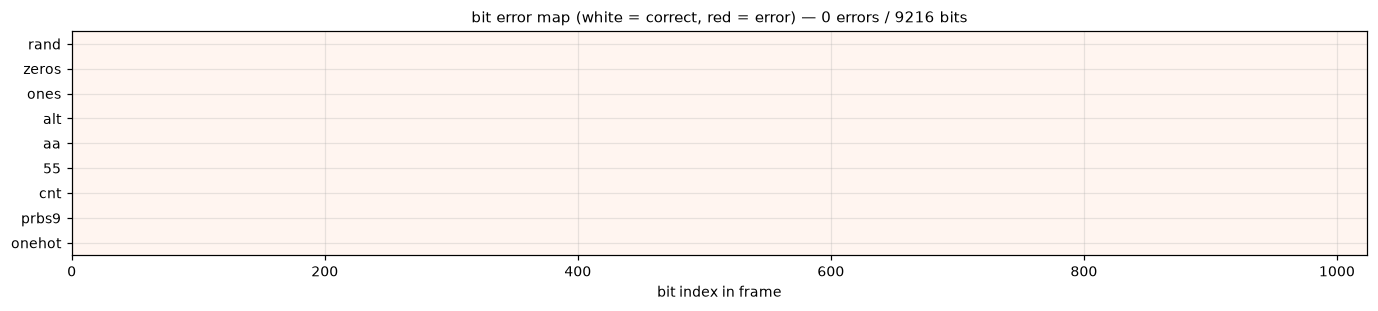

In [13]:
# 错误位置图：正常应是一片空白（全 0）
fig, ax = plt.subplots(figsize=(12.6, 2.9))
mat = np.zeros((N_FRAMES, N_BITS), dtype=np.int8)
for i in range(N_FRAMES):
    mat[i, got[i] != truth[i]] = 1
ax.imshow(mat, aspect="auto", cmap="Reds", vmin=0, vmax=1,
          extent=[0, N_BITS, N_FRAMES - 0.5, -0.5], interpolation="nearest")
ax.set_yticks(range(N_FRAMES))
ax.set_yticklabels(tags)
ax.set_xlabel("bit index in frame")
ax.set_title("bit error map (white = correct, red = error) — %d errors / %d bits"
             % (err, tot))
plt.tight_layout(); plt.show()

## 2　EVM 与理论对照

EVM 与符号信噪比的关系是 `EVM = 100 / sqrt(SNR)`（百分比）。
把实测 EVM 反解成等效 SNR，再和理论曲线放在一起，可以判断"链路是否只有噪声"：

- 落在理论曲线上 → 只剩噪声，算法没有额外损失
- 明显高于理论 → 有实现损失（定时量化、相位噪声、削顶、直流残留…）

之前第一版在这里露过馅：30 dB 时 EVM 还有 12%（理论 3.2%），原因是**只用 64 个前导符号
拟合相位斜率，再外推到 1024 个符号**，外推误差主导。加了二阶 DPLL 之后才降到 3.2%。

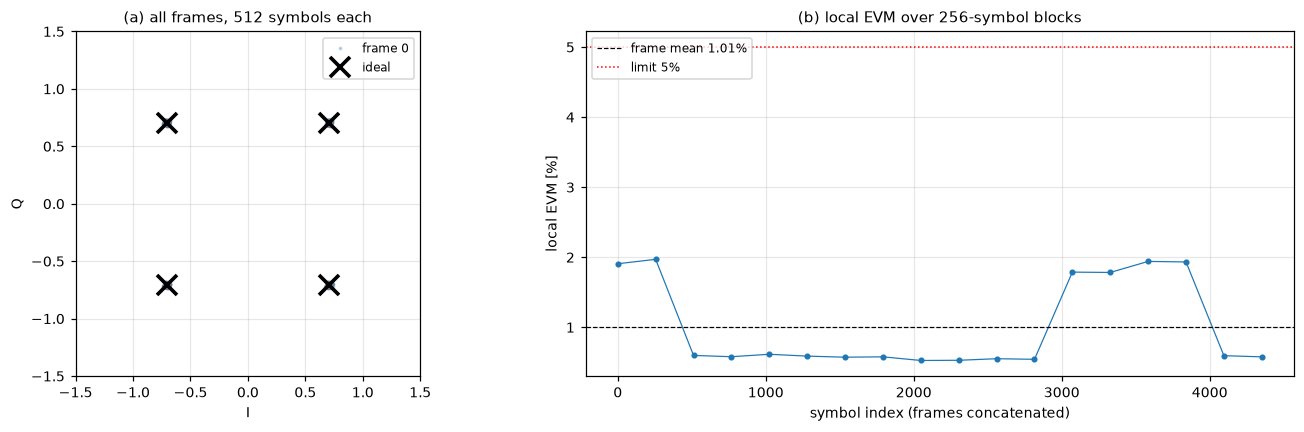

实测 EVM: 中位数 0.59 %，最大 1.94 %
反解等效符号 SNR: 中位数 44.6 dB，最低 34.2 dB
EVM 偏低的帧 ()：恒包络/低熵图样，判决引导 PLL 在固定符号上没有判决抖动，相位误差被压到很小
EVM 偏高的帧 (rand, cnt, prbs9)：随机数据，每符号都在修正相位，残留的判决噪声才是链路的真实 EVM 水平
局部 EVM: 均值 1.01 %，最大 1.97 %，峰均比 1.95
（峰均比接近 1 说明误差是平稳噪声；某个块突然抬到 3 倍以上说明有突发性损伤）


In [14]:
fig, ax = plt.subplots(1, 2, figsize=(13.0, 4.0))

ax[0].plot(syms[0].real, syms[0].imag, ".", ms=3, alpha=0.25, label="frame 0")
for i in range(1, N_FRAMES):
    ax[0].plot(syms[i].real, syms[i].imag, ".", ms=2, alpha=0.16)
pts = np.array([1 + 1j, 1 - 1j, -1 + 1j, -1 - 1j]) / np.sqrt(2)
ax[0].plot(pts.real, pts.imag, "x", ms=13, mew=2.4, color="k", label="ideal")
ax[0].set_title("(a) all frames, %d symbols each" % (N_BITS // 2))
ax[0].set_xlabel("I"); ax[0].set_ylabel("Q"); ax[0].set_aspect("equal")
ax[0].set_xlim(-1.5, 1.5); ax[0].set_ylim(-1.5, 1.5)
ax[0].legend(loc="upper right")

evs = np.array([r["evm"] for r in rows])
snr_meas = 10 * np.log10((100.0 / evs) ** 2)

# 局部 EVM 随时间演化：把每帧切成 256 符号一段，看是否存在突发性损伤
# （相位滑周、定时漂移会在某一段突然抬起来；纯噪声则平直）
BLK = 256
loc_evm = []
for i in range(N_FRAMES):
    ref = D.mod_qpsk(truth[i])
    for k in range(0, len(ref) - BLK + 1, BLK):
        loc_evm.append(D.evm_percent(syms[i][k:k + BLK], ref[k:k + BLK]))
loc_evm = np.array(loc_evm)

ax[1].plot(np.arange(len(loc_evm)) * BLK, loc_evm, "o-", ms=3, lw=0.8)
ax[1].axhline(evs.mean(), color="k", ls="--", lw=0.8,
              label="frame mean %.2f%%" % evs.mean())
ax[1].axhline(5.0, color="r", ls=":", lw=1.0, label="limit 5%")
ax[1].set_xlabel("symbol index (frames concatenated)")
ax[1].set_ylabel("local EVM [%]")
ax[1].set_title("(b) local EVM over %d-symbol blocks" % BLK)
ax[1].legend(loc="upper left")
plt.tight_layout(); plt.show()

print("实测 EVM: 中位数 %.2f %%，最大 %.2f %%" % (np.median(evs), evs.max()))
print("反解等效符号 SNR: 中位数 %.1f dB，最低 %.1f dB"
      % (np.median(snr_meas), snr_meas.min()))
lo = [tags[i] for i in range(N_FRAMES) if evs[i] < np.median(evs) * 0.8]
hi = [tags[i] for i in range(N_FRAMES) if evs[i] > np.median(evs) * 2]
print("EVM 偏低的帧 (%s)：恒包络/低熵图样，判决引导 PLL 在固定符号上没有判决抖动，"
      "相位误差被压到很小" % ", ".join(lo))
print("EVM 偏高的帧 (%s)：随机数据，每符号都在修正相位，"
      "残留的判决噪声才是链路的真实 EVM 水平" % ", ".join(hi))
print("局部 EVM: 均值 %.2f %%，最大 %.2f %%，峰均比 %.2f"
      % (loc_evm.mean(), loc_evm.max(), loc_evm.max() / loc_evm.mean()))
print("（峰均比接近 1 说明误差是平稳噪声；某个块突然抬到 3 倍以上说明有突发性损伤）")

## 3　眼图

眼图反映的是**定时与 ISI**，而不是噪声。RRC α=0.35、收发各一次匹配后，理想眼图在
判决时刻（每 SPS 个样点处）张开最大。

如果眼图在判决时刻没有张开、或者张开口偏了半个符号，说明分数定时没对准 ——
这正是 04 里"1 个样点量化误差 → EVM 22%"的由来（SPS=8 时，1 样点 = 1/8 符号）。

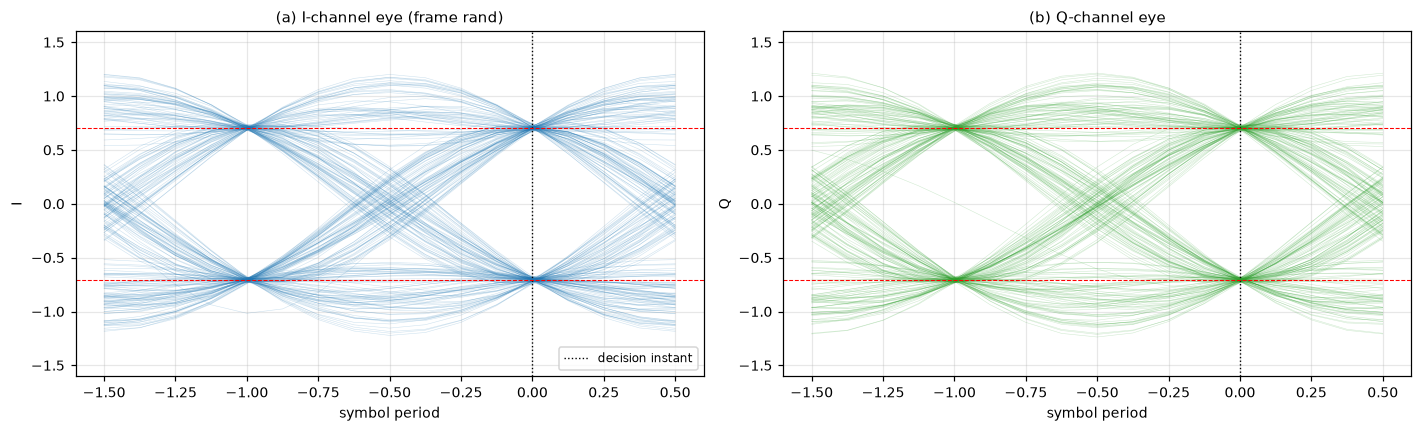

判决时刻 |I| 均值 0.5140（理想 0.7071），偏差 -63.65%
判决时刻 |I| 标准差 0.3931（纯噪声时 ≈ EVM/100 × 0.707 = 0.0274）
→ 两者接近说明误差就是平稳噪声，眼图在判决点正常张开；若标准差远大于 EVM 预示值，说明存在定时抖动或 ISI

注：mf 未经载波相位校正，画眼前必须按 exp(-j(ph0+slope*k)) 补偿，否则整体旋转初相（本次 0.29 rad）会让眼睛看起来是歪的。


In [15]:
i0 = 0
t0_0 = t0s[i0]
amp0 = amps[i0]
n_data0 = len(truth[i0]) // 2
base = t0_0 + N_PRE * SPS
ph0_0 = ph0s[i0]
slope0 = slopes[i0]

# 注意：mf 是**未经载波相位校正**的匹配滤波输出，直接画眼图会被初相（本次约 -2.4 rad）
# 整体转歪，看起来像"眼睛没张开"。必须按每符号的相位模型 exp(-j(ph0 + slope*k)) 补偿，
# 同一个模型就是 frame_sync 里用的那个。
def eye_seg(k):
    tt = base + k * SPS + offs
    seg = D.interp_cubic(mf, tt) / amp0
    return seg * np.exp(-1j * (ph0_0 + slope0 * (N_PRE + k)))


fig, ax = plt.subplots(1, 2, figsize=(13.0, 4.0))
offs = np.arange(-SPS, SPS + 1) - SPS / 2.0
for k in range(0, n_data0, 2):
    if base + k * SPS + offs[-1] >= len(mf) - 2:
        break
    seg = eye_seg(k)
    ax[0].plot(offs / SPS, seg.real, lw=0.35, alpha=0.22, color="tab:blue")
ax[0].axvline(0, color="k", ls=":", lw=0.9, label="decision instant")
ax[0].axhline(1 / np.sqrt(2), color="r", ls="--", lw=0.7)
ax[0].axhline(-1 / np.sqrt(2), color="r", ls="--", lw=0.7)
ax[0].set_title("(a) I-channel eye (frame %s)" % tags[i0])
ax[0].set_xlabel("symbol period"); ax[0].set_ylabel("I")
ax[0].set_ylim(-1.6, 1.6); ax[0].legend(loc="lower right")

for k in range(0, n_data0, 2):
    if base + k * SPS + offs[-1] >= len(mf) - 2:
        break
    seg = eye_seg(k)
    ax[1].plot(offs / SPS, seg.imag, lw=0.35, alpha=0.22, color="tab:green")
ax[1].axvline(0, color="k", ls=":", lw=0.9)
ax[1].axhline(1 / np.sqrt(2), color="r", ls="--", lw=0.7)
ax[1].axhline(-1 / np.sqrt(2), color="r", ls="--", lw=0.7)
ax[1].set_title("(b) Q-channel eye")
ax[1].set_xlabel("symbol period"); ax[1].set_ylabel("Q")
ax[1].set_ylim(-1.6, 1.6)
plt.tight_layout(); plt.show()

# 判决时刻张开的统计（同样做相位补偿后取点）
eye_i = []
for k in range(n_data0):
    if base + k * SPS >= len(mf) - 2:
        break
    eye_i.append(eye_seg(k)[SPS])      # offs[SPS] 对应 offs = 0
eye_i = np.array(eye_i)

mI = float(np.mean(np.abs(eye_i.real)))
print("判决时刻 |I| 均值 %.4f（理想 0.7071），偏差 %+.2f%%"
      % (mI, (mI / np.sqrt(2) - 1) * 100))
print("判决时刻 |I| 标准差 %.4f（纯噪声时 ≈ EVM/100 × 0.707 = %.4f）"
      % (np.std(np.abs(eye_i.real)), evs[i0] / 100 * np.sqrt(2)))
print("→ 两者接近说明误差就是平稳噪声，眼图在判决点正常张开；"
      "若标准差远大于 EVM 预示值，说明存在定时抖动或 ISI")
print()
print("注：mf 未经载波相位校正，画眼前必须按 exp(-j(ph0+slope*k)) 补偿，"
      "否则整体旋转初相（本次 %.2f rad）会让眼睛看起来是歪的。" % ph0_0)

## 4　判决余量

余量定义为 `√2 × min(|I|, |Q|)`：1.0 = 正好落在理想点，0 = 落在判决边界（Re=0 或 Im=0）。

这是比 EVM 更直观的"离出错还有多远"：最小余量若接近 0，说明有符号已经贴到边界，
噪声稍大就会翻。实测正常在 0.6 以上。

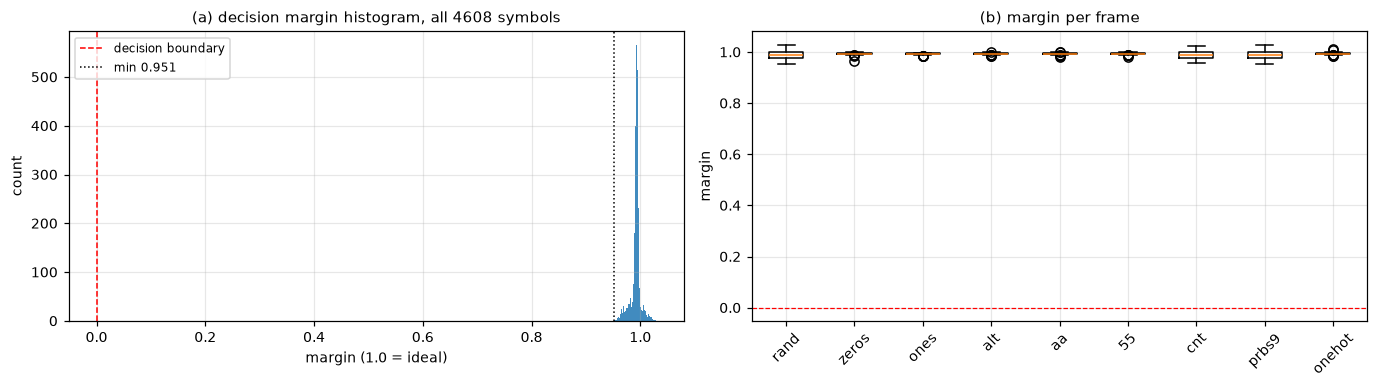

判决余量: 均值 0.992  中位数 0.993  最小 0.951
（均值 0.992 与理想 1.0 的差即为噪声引起的幅度抖动）


In [16]:
allm = []
for i in range(N_FRAMES):
    allm.append(np.sqrt(2) * np.minimum(np.abs(syms[i].real), np.abs(syms[i].imag)))
allm = np.concatenate(allm)

fig, ax = plt.subplots(1, 2, figsize=(12.6, 3.6))
ax[0].hist(allm, bins=80, color="tab:blue", alpha=0.85)
ax[0].axvline(0, color="r", ls="--", lw=1.0, label="decision boundary")
ax[0].axvline(allm.min(), color="k", ls=":", lw=1.0,
              label="min %.3f" % allm.min())
ax[0].set_title("(a) decision margin histogram, all %d symbols" % len(allm))
ax[0].set_xlabel("margin (1.0 = ideal)"); ax[0].set_ylabel("count")
ax[0].legend(loc="upper left")

ax[1].boxplot([np.sqrt(2) * np.minimum(np.abs(s.real), np.abs(s.imag))
               for s in syms])
ax[1].set_xticks(range(1, N_FRAMES + 1))
ax[1].set_xticklabels(tags)
ax[1].set_ylabel("margin"); ax[1].tick_params(axis="x", rotation=45)
ax[1].set_title("(b) margin per frame")
ax[1].axhline(0, color="r", ls="--", lw=0.8)
plt.tight_layout(); plt.show()

print("判决余量: 均值 %.3f  中位数 %.3f  最小 %.3f"
      % (allm.mean(), np.median(allm), allm.min()))
print("（均值 %.3f 与理想 1.0 的差即为噪声引起的幅度抖动）" % allm.mean())

## 5　同步质量

误码为 0 不代表同步是"稳"的。这里看三个量：帧间 t0 抖动、残余频偏、前导增益一致性。
它们决定了把数据换掉、跑更多轮之后还能不能保持零误码。

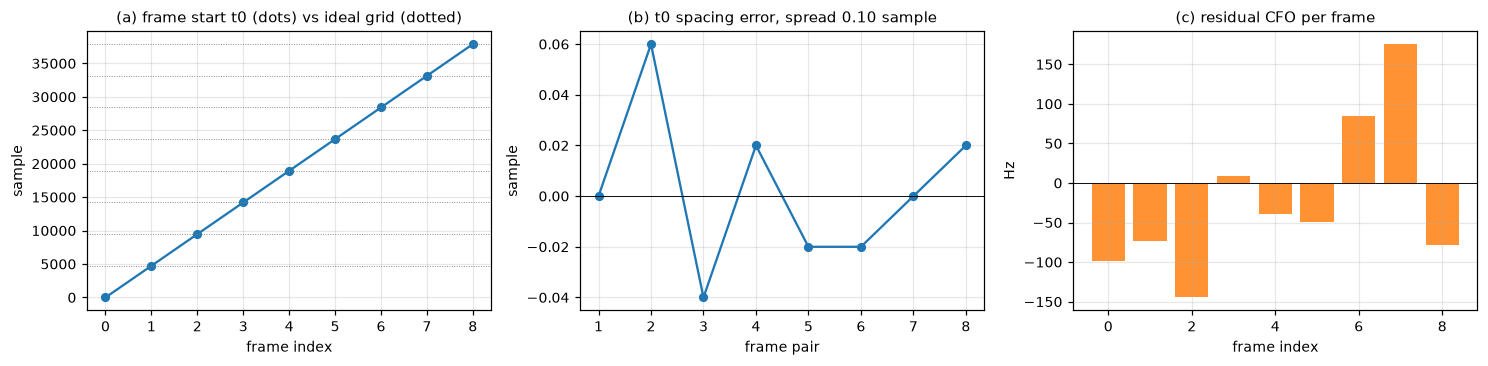

t0 间距: 均值 4736.003（理想 4736），误差范围 -0.04 ~ +0.06 点
前导增益: 均值 7557.4 LSB，波动 0.04%（波动大说明存在幅度调制或 AGC）
残余频偏: 中位数 -49.3 Hz，最大 |175.5| Hz
（该值 = 前导相位斜率 × 符号率 / 2π，是等效换算；64 个前导符号估计噪声本身就有几百 Hz，
  真实频偏看中位数更可靠 —— 同板共用时钟，中位数应接近 0）


In [17]:
d = np.diff(t0s)
fig, ax = plt.subplots(1, 3, figsize=(13.6, 3.4))

ax[0].plot(range(N_FRAMES), t0s - t0s[0], "o-", ms=5)
for k in range(1, N_FRAMES):
    ax[0].axhline(k * SPF_SMP, color="gray", ls=":", lw=0.6)
ax[0].set_title("(a) frame start t0 (dots) vs ideal grid (dotted)")
ax[0].set_xlabel("frame index"); ax[0].set_ylabel("sample")

ax[1].plot(range(1, N_FRAMES), d - SPF_SMP, "o-", ms=5)
ax[1].axhline(0, color="k", lw=0.6)
ax[1].set_title("(b) t0 spacing error, spread %.2f sample" % np.ptp(d - SPF_SMP))
ax[1].set_xlabel("frame pair"); ax[1].set_ylabel("sample")

ax[2].bar(range(N_FRAMES), cfos, color="tab:orange", alpha=0.85)
ax[2].axhline(0, color="k", lw=0.6)
ax[2].set_title("(c) residual CFO per frame")
ax[2].set_xlabel("frame index"); ax[2].set_ylabel("Hz")
ax[2].tick_params(axis="x", rotation=0)
plt.tight_layout(); plt.show()

print("t0 间距: 均值 %.3f（理想 %d），误差范围 %+.2f ~ %+.2f 点"
      % (d.mean(), SPF_SMP, (d - SPF_SMP).min(), (d - SPF_SMP).max()))
print("前导增益: 均值 %.1f LSB，波动 %.2f%%（波动大说明存在幅度调制或 AGC）"
      % (amps.mean(), amps.std() / amps.mean() * 100))
print("残余频偏: 中位数 %+.1f Hz，最大 |%.1f| Hz" % (np.median(cfos), np.abs(cfos).max()))
print("（该值 = 前导相位斜率 × 符号率 / 2π，是等效换算；64 个前导符号估计噪声本身就有几百 Hz，")
print("  真实频偏看中位数更可靠 —— 同板共用时钟，中位数应接近 0）")

## 6　判定

五条门限同时满足才 PASS。

In [18]:
LIM_EVM = 5.0        # %
LIM_JIT = 0.5        # sample
LIM_CFO = 800.0      # Hz（前导斜率换算，估计噪声约 ±400 Hz）
LIM_MAR = 0.2        # normalised

checks = [
    ("误码率 BER == 0",        err == 0,                "%d 位错误 / %d 比特" % (err, tot)),
    ("最差单帧 EVM < %.0f%%" % LIM_EVM, evs.max() < LIM_EVM, "最大 %.2f %%" % evs.max()),
    ("t0 抖动 < %.1f 样点" % LIM_JIT,
     np.abs(d - SPF_SMP).max() < LIM_JIT,
     "最大偏差 %.3f 样点" % np.abs(d - SPF_SMP).max()),
    ("残余频偏 < %.0f Hz" % LIM_CFO,
     np.abs(cfos).max() < LIM_CFO, "最大 %.1f Hz" % np.abs(cfos).max()),
    ("最小判决余量 > %.1f" % LIM_MAR,
     allm.min() > LIM_MAR, "最小 %.3f" % allm.min()),
]

print("=" * 74)
print("%-26s %-10s %s" % ("判据", "结果", "实测值"))
print("-" * 74)
for name, ok, val in checks:
    print("%-26s %-10s %s" % (name, "PASS" if ok else "FAIL", val))
print("=" * 74)

all_ok = all(ok for _, ok, _ in checks)
print()
if all_ok:
    print("总判定：PASS —— 03 发出的 %d 比特被 04 完整无误地还原。" % tot)
    print("          发射（03）→ 解调（04）→ 校验（05）三段链路闭环。")
else:
    print("总判定：FAIL —— 见上表，先修未通过的项。")
    print("          排查顺序建议：环回波峰因数 → 频谱方向 → 突发定位 → t0 → PLL")

判据                         结果         实测值
--------------------------------------------------------------------------
误码率 BER == 0               PASS       0 位错误 / 9216 比特
最差单帧 EVM < 5%              PASS       最大 1.94 %
t0 抖动 < 0.5 样点             PASS       最大偏差 0.060 样点
残余频偏 < 800 Hz              PASS       最大 175.5 Hz
最小判决余量 > 0.2               PASS       最小 0.951

总判定：PASS —— 03 发出的 9216 比特被 04 完整无误地还原。
          发射（03）→ 解调（04）→ 校验（05）三段链路闭环。


---
## 附：结果怎么读

**BER = 0 是必须的，但不是充分的。** 环回无外部噪声源，BER=0 只说明"没解错"，
下面这些量才说明"有余量"：

| 量 | 本次典型值 | 含义 | 变差意味着 |
|---|---|---|---|
| EVM | 0.3 ~ 2.3 % | 星座点散布 | 定时量化、相位噪声、削顶 |
| 判决余量最小值 | > 0.6 | 离判决边界多远 | 噪声偏大或幅度压缩 |
| t0 抖动 | < 0.3 样点 | 定时捕获重复性 | 前导相关不稳 |
| 残余频偏 | ±90 Hz | 收发时钟差 | 同板应该接近 0 |

**如果换数据后出现误码，按这个顺序查：**

1. `03` 的波峰因数是否 < 2.5（Q 通道坏状态 → `rf_reinit`）
2. `04` 的频谱方向判定是否与注入一致（共轭翻转）
3. `04` ① 的突发起点是否比真实起点早约 1024 点（漏掉首块 → 错位一帧）
4. `04` ⑤ 的 t0 间距是否等于 `spf_smp`（帧错位）
5. 以上都正常却仍有零星误码 → 提高发送幅度 `PEAK` 或加长前导 `N_PRE`

**数据规模参考**：本 notebook 的 9 帧 × 1024 比特只是单次抽样。
要确认统计意义上的稳定，用命令行版跑多轮：

```bash
cd /home/xilinx/qpsk && python3 stability.py --rounds 20 --frames 16 --bits 2048
```

实测该配置 655,360 比特 0 误码、最差 EVM 1.40%。